# RSICD Whole-Image Zero-Shot Classification with RemoteCLIP
### Baseline evaluation: RemoteCLIP zero-shot accuracy against RSICD's 31 scene classes

**Pipeline overview:**
1. Setup — mount Drive, install dependencies, load RemoteCLIP
2. Build the 31-class vocabulary from class folder filenames
3. Build multi-template (ensembled) text embeddings per class
4. Build ground truth (image → true class) from the per-class txt files
5. Run whole-image zero-shot classification across the dataset
6. Compute overall accuracy
7. Per-class confusion analysis


## 1. Setup — Mount Drive, Install Dependencies, Load RemoteCLIP

In [1]:
!pip install -q open-clip-torch huggingface_hub matplotlib scikit-learn seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 53.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 3.3 MB/s eta 0:00:00


In [2]:
import os
import time
import torch
import torch.nn.functional as F
import open_clip
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from huggingface_hub import hf_hub_download
from collections import Counter

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cuda


In [3]:
# Dataset paths
BASE_DIR = "/kaggle/input/datasets/vedantbarhate007/rsicd-eric/RSICD_optimal-master"
IMG_DIR = os.path.join(BASE_DIR, "RSICD_images")
CLASSES_DIR = os.path.join(BASE_DIR, "txtclasses_rsicd")

assert os.path.isdir(IMG_DIR), f"Image dir not found: {IMG_DIR}"
assert os.path.isdir(CLASSES_DIR), f"Classes dir not found: {CLASSES_DIR}"
print("Paths OK")

Paths OK


In [4]:
print("Downloading RemoteCLIP weights...")
ckpt_path = hf_hub_download("chendelong/RemoteCLIP", "RemoteCLIP-ViT-B-32.pt")

model_name = 'ViT-B-32'
model, _, preprocess = open_clip.create_model_and_transforms(model_name)
tokenizer = open_clip.get_tokenizer(model_name)

ckpt = torch.load(ckpt_path, map_location=device)
model.load_state_dict(ckpt)
model = model.to(device).eval()
print("RemoteCLIP loaded!")

RemoteCLIP-ViT-B-32.pt:   0%|          | 0.00/605M [00:00<?, ?B/s]

RemoteCLIP loaded!


## 2. Build the 31-Class Vocabulary

The class folder contains one `.txt` file per class (e.g. `airport.txt`), each listing the image
filenames belonging to that class. We derive the class list directly from these filenames, and
map concatenated names (e.g. `denseresidential`) to readable phrases for better CLIP text prompts.

In [5]:
files = sorted(f for f in os.listdir(CLASSES_DIR) if f.endswith(".txt"))
classes = [os.path.splitext(f)[0].lower() for f in files]

print(f"Found {len(classes)} classes")
print(classes)

Found 31 classes
['airport', 'bareland', 'baseballfield', 'beach', 'bridge', 'center', 'church', 'commercial', 'denseresidential', 'desert', 'farmland', 'forest', 'industrial', 'meadow', 'mediumresidential', 'mountain', 'park', 'parking', 'playground', 'pond', 'port', 'railwaystation', 'resort', 'river', 'school', 'sparseresidential', 'square', 'stadium', 'storagetanks', 'viaduct', 'playfields']


In [6]:
# Explicit mapping for concatenated class names -> readable phrases
readable_map = {
    "bareland": "bare land",
    "baseballfield": "baseball field",
    "denseresidential": "dense residential",
    "mediumresidential": "medium residential",
    "sparseresidential": "sparse residential",
    "railwaystation": "railway station",
    "storagetanks": "storage tanks",
    "playfields": "play fields",
}

readable_classes = [readable_map.get(c, c) for c in classes]
print(list(zip(classes, readable_classes)))

[('airport', 'airport'), ('bareland', 'bare land'), ('baseballfield', 'baseball field'), ('beach', 'beach'), ('bridge', 'bridge'), ('center', 'center'), ('church', 'church'), ('commercial', 'commercial'), ('denseresidential', 'dense residential'), ('desert', 'desert'), ('farmland', 'farmland'), ('forest', 'forest'), ('industrial', 'industrial'), ('meadow', 'meadow'), ('mediumresidential', 'medium residential'), ('mountain', 'mountain'), ('park', 'park'), ('parking', 'parking'), ('playground', 'playground'), ('pond', 'pond'), ('port', 'port'), ('railwaystation', 'railway station'), ('resort', 'resort'), ('river', 'river'), ('school', 'school'), ('sparseresidential', 'sparse residential'), ('square', 'square'), ('stadium', 'stadium'), ('storagetanks', 'storage tanks'), ('viaduct', 'viaduct'), ('playfields', 'play fields')]


## 3. Build Ensembled Text Embeddings

Using a single prompt template per class (e.g. only `"a satellite photo of X"`) risks CLIP's
known zero-shot class-imbalance bias, where certain classes dominate predictions regardless of
actual image content. We mitigate this by averaging embeddings across multiple prompt templates
per class (standard CLIP zero-shot ensembling practice).

In [7]:
prompt_templates = [
    "a satellite photo of {}",
    "an aerial view of {}",
    "a remote sensing image of {}",
    "a satellite image showing {}",
    "an overhead photo of {}",
    "a bird's eye view of {}",
]

with torch.no_grad():
    all_class_features = []
    for c in readable_classes:
        prompts = [t.format(c) for t in prompt_templates]
        tokens = tokenizer(prompts).to(device)
        feats = model.encode_text(tokens)                 # [num_templates, 512]
        feats = feats / feats.norm(dim=-1, keepdim=True)   # normalize each template embedding
        avg_feat = feats.mean(dim=0)                       # average across templates
        avg_feat = avg_feat / avg_feat.norm()               # re-normalize after averaging
        all_class_features.append(avg_feat)

    text_features = torch.stack(all_class_features)         # [31, 512]

print("Text embeddings shape:", text_features.shape)

Text embeddings shape: torch.Size([31, 512])


## 4. Build Ground Truth (Image → True Class)

Each class `.txt` file lists the filenames of images belonging to that class. We invert this into
a single `filename -> class_index` lookup dictionary for accuracy evaluation.

In [8]:
ground_truth = {}  # filename -> class index

for class_idx, fname in enumerate(files):
    filepath = os.path.join(CLASSES_DIR, fname)
    with open(filepath) as f:
        image_names = [line.strip() for line in f if line.strip()]
    for img_name in image_names:
        ground_truth[img_name] = class_idx

print(f"Total labeled images: {len(ground_truth)}")

# Sanity check
sample_keys = list(ground_truth.keys())[:5]
for k in sample_keys:
    print(k, "->", classes[ground_truth[k]])

Total labeled images: 10921
00433.jpg -> airport
00434.jpg -> airport
00435.jpg -> airport
00436.jpg -> airport
00437.jpg -> airport


## 5. Whole-Image Zero-Shot Classification

Classify every ground-truth image against the 31-class ensembled text embeddings, in batches.
Missing/corrupt files are skipped defensively rather than crashing the run.

In [12]:
# Quick empirical check before committing to a large batch size for the full run
test_batch_sizes = [64, 128, 256, 512]

for bs in test_batch_sizes:
    try:
        dummy_batch = torch.randn(bs, 3, 224, 224).to(device)
        with torch.no_grad():
            _ = model.encode_image(dummy_batch)
        print(f"Batch size {bs}: OK")
        torch.cuda.empty_cache()
    except RuntimeError as e:
        print(f"Batch size {bs}: FAILED — {e}")
        torch.cuda.empty_cache()
        break

Batch size 64: OK
Batch size 128: OK
Batch size 256: OK
Batch size 512: OK


In [13]:
def run_zero_shot_classification(ground_truth, img_dir, model, preprocess, text_features,
                                  batch_size=512, verbose_every=20):
    correct = 0
    total = 0
    predictions_log = []  # (filename, true_class_idx, predicted_class_idx)

    image_names = list(ground_truth.keys())
    start_time = time.time()

    for i in range(0, len(image_names), batch_size):
        batch_names = image_names[i:i + batch_size]
        batch_imgs = []
        valid_names = []

        for name in batch_names:
            img_path = os.path.join(img_dir, name)
            if not os.path.exists(img_path):
                continue
            try:
                img = Image.open(img_path).convert("RGB")
                batch_imgs.append(preprocess(img))
                valid_names.append(name)
            except Exception as e:
                print(f"Skipping {name}: {e}")
                continue

        if not batch_imgs:
            continue

        batch_tensor = torch.stack(batch_imgs).to(device)

        with torch.no_grad():
            image_features = model.encode_image(batch_tensor)
            image_features = image_features / image_features.norm(dim=-1, keepdim=True)
            sim = image_features @ text_features.T
            preds = sim.argmax(dim=-1).cpu().numpy()

        for name, pred in zip(valid_names, preds):
            true_class = ground_truth[name]
            predictions_log.append((name, true_class, pred))
            if pred == true_class:
                correct += 1
            total += 1

        if (i // batch_size) % verbose_every == 0:
            elapsed = time.time() - start_time
            acc_so_far = correct / total if total else 0.0
            print(f"Processed {total} images, running accuracy: {acc_so_far:.4f}, elapsed: {elapsed:.1f}s")

    final_acc = correct / total if total else 0.0
    print(f"\nFinal accuracy: {correct}/{total} = {final_acc:.4f}")
    return predictions_log, final_acc

In [18]:
predictions_log, final_accuracy = run_zero_shot_classification(
    ground_truth, IMG_DIR, model, preprocess, text_features, batch_size=256, verbose_every=5
)

Processed 256 images, running accuracy: 0.9180, elapsed: 1.7s
Processed 1536 images, running accuracy: 0.9447, elapsed: 9.8s
Processed 2816 images, running accuracy: 0.9400, elapsed: 17.9s
Processed 4096 images, running accuracy: 0.9407, elapsed: 26.3s
Processed 5376 images, running accuracy: 0.9403, elapsed: 34.7s
Processed 6656 images, running accuracy: 0.9405, elapsed: 43.1s
Processed 7936 images, running accuracy: 0.9371, elapsed: 51.5s
Processed 9216 images, running accuracy: 0.9272, elapsed: 60.0s
Processed 10496 images, running accuracy: 0.9154, elapsed: 68.6s

Final accuracy: 9670/10921 = 0.8855


## 6. Per-Class Confusion Analysis

Beyond overall accuracy, we check *which* classes get confused with which — this also tells us
whether the "hub" class-imbalance bias observed in earlier patch-level experiments persists at
the whole-image level.

In [19]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

y_true = [t for (_, t, _) in predictions_log]
y_pred = [p for (_, _, p) in predictions_log]

print(classification_report(y_true, y_pred, target_names=readable_classes, zero_division=0))

                    precision    recall  f1-score   support

           airport       0.99      0.90      0.95       420
         bare land       0.94      0.91      0.92       310
    baseball field       0.86      0.96      0.91       276
             beach       0.91      1.00      0.95       400
            bridge       0.97      0.95      0.96       459
            center       0.74      0.89      0.81       260
            church       0.94      0.97      0.96       240
        commercial       0.91      0.92      0.92       350
 dense residential       0.97      0.91      0.94       410
            desert       0.92      0.98      0.95       300
          farmland       0.99      0.96      0.97       370
            forest       0.89      0.97      0.93       250
        industrial       0.98      0.83      0.90       390
            meadow       0.90      1.00      0.95       280
medium residential       0.89      0.96      0.92       290
          mountain       1.00      0.99

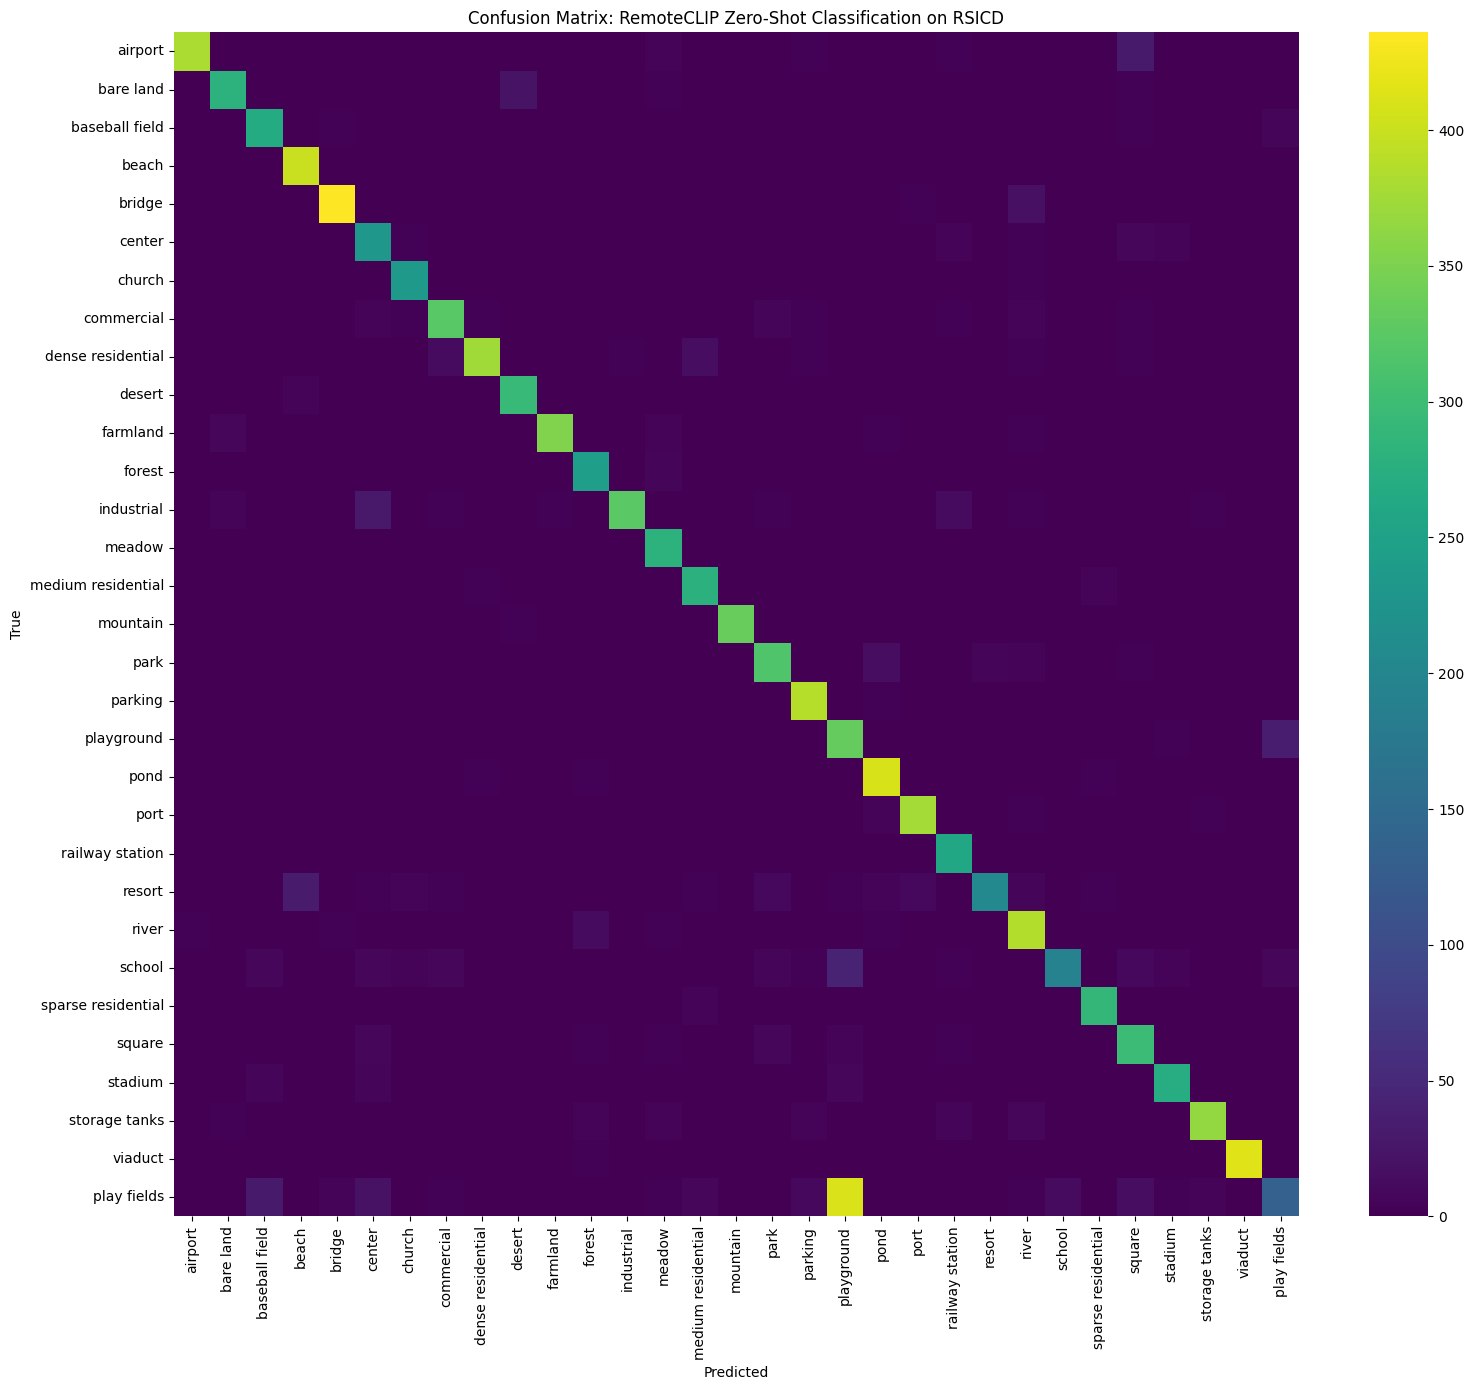

In [20]:
cm = confusion_matrix(y_true, y_pred, labels=list(range(len(classes))))

plt.figure(figsize=(16, 14))
sns.heatmap(cm, xticklabels=readable_classes, yticklabels=readable_classes,
            cmap="viridis", annot=False, cbar=True)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix: RemoteCLIP Zero-Shot Classification on RSICD")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [21]:
# Prediction frequency check -- is any single class dominating regardless of ground truth?
pred_counts = Counter(y_pred)
print("Predicted class frequency (top 15):")
for idx, count in pred_counts.most_common(15):
    print(f"  {readable_classes[idx]}: {count} ({100*count/len(y_pred):.1f}%)")

true_counts = Counter(y_true)
print("\nTrue class frequency (top 15), for comparison:")
for idx, count in true_counts.most_common(15):
    print(f"  {readable_classes[idx]}: {count} ({100*count/len(y_true):.1f}%)")

Predicted class frequency (top 15):
  playground: 804 (7.4%)
  bridge: 450 (4.1%)
  pond: 446 (4.1%)
  river: 445 (4.1%)
  beach: 438 (4.0%)
  viaduct: 419 (3.8%)
  parking: 413 (3.8%)
  port: 395 (3.6%)
  airport: 383 (3.5%)
  dense residential: 383 (3.5%)
  storage tanks: 376 (3.4%)
  square: 370 (3.4%)
  farmland: 359 (3.3%)
  commercial: 353 (3.2%)
  park: 348 (3.2%)

True class frequency (top 15), for comparison:
  play fields: 661 (6.1%)
  bridge: 459 (4.2%)
  airport: 420 (3.8%)
  pond: 420 (3.8%)
  viaduct: 420 (3.8%)
  dense residential: 410 (3.8%)
  river: 410 (3.8%)
  beach: 400 (3.7%)
  storage tanks: 396 (3.6%)
  industrial: 390 (3.6%)
  parking: 390 (3.6%)
  port: 389 (3.6%)
  farmland: 370 (3.4%)
  playground: 370 (3.4%)
  commercial: 350 (3.2%)


### Notes / Next Steps
- If overall accuracy is low and/or a small number of classes dominate predicted frequency far
  more than their true frequency, this confirms the CLIP zero-shot class-imbalance bias observed
  earlier at the patch level — worth investigating bias-correction (e.g. per-class similarity
  mean-centering) as a next step.
- This whole-image baseline result is the reference point before moving to patch-level /
  raster-based classification.
